# Inference-time scaling via self-refinement

# 5.2 Loading a pretrained model

In [2]:
import torch
from reasoning_from_scratch.ch02 import get_device
from reasoning_from_scratch.ch03 import (
     load_model_and_tokenizer
)

device = get_device()
device = torch.device("cpu")

model, tokenizer = load_model_and_tokenizer(
    which_model="base",
    device=device,
    use_compile=False
)

Using CPU
✓ qwen3\qwen3-0.6B-base.pth already up-to-date


In [2]:
from reasoning_from_scratch.ch03 import render_prompt
from reasoning_from_scratch.ch04 import (
    generate_text_stream_concat_flex,
    generate_text_top_p_stream_cache
)

raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)
prompt = render_prompt(raw_prompt)
prompt_cot = prompt + "\n\nExplain step by step."

torch.manual_seed(0)
response_1 = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.9,
    top_p=0.9
)

 ### Step 1: Understand the problem

The problem states that half the value of \(3x - 9\) is equal to \(x + 37\). We need to find the value of \(x\).

### Step 2: Translate the problem into an equation

Let's translate the given statement into an equation. Half of \(3x - 9\) is equal to \(x + 37\).

\[
\frac{1}{2}(3x - 9) = x + 37
\]

### Step 3: Solve the equation

To solve for \(x\), we'll first eliminate the fraction by multiplying both sides of the equation by 2:

\[
2 \times \frac{1}{2}(3x - 9) = 2 \times (x + 37)
\]

This simplifies to:

\[
3x - 9 = 2x + 74
\]

### Step 4: Isolate the variable \(x\)

Now, we'll isolate \(x\) by subtracting \(2x\) from both sides of the equation:

\[
3x - 2x - 9 = 74
\]

Simplifying this, we get:

\[
x - 9 = 74
\]

### Step 5: Solve for \(x\)

Next, we'll add 9 to both sides to solve for \(x\):

\[
x - 9 + 9 = 74 + 9
\]

This simplifies to:

\[
x = 83
\]

### Step 6: Verify the solution

To ensure our solution is correct, we'll substitute \(x = 83

In [3]:
torch.manual_seed(3)
response_2 = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.9,
    top_p=0.9, 
)

 We start with the equation:

\[
\frac{1}{2} \times (3x - 9) = x + 37
\]

Step 1: Multiply both sides of the equation by 2 to eliminate the fraction:

\[
2 \times \frac{1}{2} \times (3x - 9) = 2 \times (x + 37)
\]

Simplifying both sides:

\[
3x - 9 = 2x + 74
\]

Step 2: Subtract \(2x\) from both sides to get all the \(x\) terms on one side:

\[
3x - 2x - 9 = 74
\]

Simplifying:

\[
x - 9 = 74
\]

Step 3: Add 9 to both sides to isolate \(x\):

\[
x - 9 + 9 = 74 + 9
\]

Simplifying:

\[
x = 83
\]

Final Answer:

\[
\boxed{83}
\]

In [4]:
print("Response 1 characters:", len(response_1))
print("Response 1 tokens:", len(tokenizer.encode(response_1)))
print("\nResponse 2 characters:", len(response_2))
print("Response 2 tokens:", len(tokenizer.encode(response_2)))

Response 1 characters: 1419
Response 1 tokens: 534

Response 2 characters: 533
Response 2 tokens: 231


# 5.3 Scoring LLM responses with a rule-based score

In [5]:
from reasoning_from_scratch.ch03 import extract_final_candidate
import math

def heuristic_score(
    answer,
    prompt=None,
    brevity_bonus=500.0,
    boxed_bonus=2.0,
    extract_bonus=1.0,
    fulltext_bonus=0.0,
):
    score = 0.0

    cand = extract_final_candidate(answer, fallback="none")
    if cand:
        score += boxed_bonus

    else:
        cand = extract_final_candidate(answer, fallback="number_only")
        if cand:
            score += extract_bonus
        else:
            cand = extract_final_candidate(
                answer, fallback="number_then_full"
            )
            if cand:
                score += fulltext_bonus

    score += 1.5 * math.exp(-len(answer) / brevity_bonus)
    return score

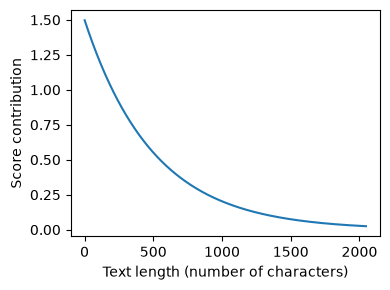

In [6]:
import matplotlib.pyplot as plt

def plot_brevity_curve(brevity_bonus, max_len=2048):
    lengths = torch.arange(1, max_len)
    scores = 1.5 * torch.exp(-lengths / brevity_bonus)

    plt.figure(figsize=(4, 3))
    plt.plot(lengths, scores)
    plt.xlabel("Text length (number of characters)")
    plt.ylabel("Score contribution")
    plt.tight_layout()
    plt.show()

plot_brevity_curve(500)

In [7]:
print(round(heuristic_score(response_1), 3))

2.088


In [8]:
print(round(heuristic_score(response_2), 3))

2.517


# Exercise 5.1: Using the heuristic scorer as a tiebreaker in self-consistency

In [18]:
from reasoning_from_scratch.ch03 import extract_final_candidate
from collections import Counter

def self_consistency_vote_ex51(
    model, tokenizer, prompt, device,
    num_samples=10, temperature=0.8, top_p=0.9, max_new_tokens=2048,
    show_progress=True, show_long_answer=False, seed=None,
):
    full_answers, short_answers = [], []
    scores = []

    for i in range(num_samples):
        if seed is not None:
            torch.manual_seed(seed + i + 1)

        answer = generate_text_stream_concat_flex(
            model=model, tokenizer=tokenizer, prompt=prompt, device=device,
            max_new_tokens=max_new_tokens, verbose=show_long_answer,
            generate_func=generate_text_top_p_stream_cache,
            temperature=temperature, top_p=top_p,
        )

        short = extract_final_candidate(
            answer, fallback="number_then_full"
        )
        scores.append(float(heuristic_score(answer)))
        full_answers.append(answer)
        short_answers.append(short)
        if show_progress:
            print(f"[Sample {i+1}/{num_samples}] → {short!r}")

    counts = Counter(short_answers)
    groups = {s: [] for s in counts}
    for idx, s in enumerate(short_answers):
        groups[s].append(idx)

    mc = counts.most_common()

    if not mc:
        majority_winners, final_answer = [], None
    else:
        top_freq = mc[0][1]
        majority_winners = [s for s, f in mc if f == top_freq]

        if len(majority_winners) == 1:
            final_answer = majority_winners[0]
        else:
            best_scores = {
                        answer: max(scores[i] for i in idxs)
                        for answer, idxs in groups.items()
                    }
            final_answer = max(
                majority_winners,
                key=lambda x: best_scores[x]
            )


    return {
        "full_answers": full_answers,
        "short_answers": short_answers,
        "counts": dict(counts),
        "groups": groups,
        "majority_winners": majority_winners,
        "final_answer": final_answer,
        "scores": scores,
    }

results = self_consistency_vote_ex51(
    model,
    tokenizer,
    prompt,
    device=device,
    num_samples=3,
    temperature=0.8,
    top_p=0.9,
    max_new_tokens=2048,
    seed=123,
    show_progress=True,
)
results

[Sample 1/3] → '83'
[Sample 2/3] → '22'
[Sample 3/3] → '54'


{'full_answers': [" To find the value of \\( x \\), let's solve the equation step by step.\n\n1. **Given Equation:**\n   \\[\n   \\frac{1}{2} \\times (3x - 9) = x + 37\n   \\]\n\n2. **Multiply Both Sides by 2 to Eliminate the Fraction:**\n   \\[\n   3x - 9 = 2(x + 37)\n   \\]\n\n3. **Distribute the 2 on the Right Side:**\n   \\[\n   3x - 9 = 2x + 74\n   \\]\n\n4. **Subtract \\( 2x \\) from Both Sides to Get the \\( x \\)-terms on One Side:**\n   \\[\n   3x - 2x - 9 = 74\n   \\]\n   \\[\n   x - 9 = 74\n   \\]\n\n5. **Add 9 to Both Sides to Solve for \\( x \\):**\n   \\[\n   x = 74 + 9\n   \\]\n   \\[\n   x = 83\n   \\]\n\n**Final Answer:**\n\\[\n\\boxed{83}\n\\]",
  ' \\boxed{22}',
  ' $\\boxed{54}$'],
 'short_answers': ['83', '22', '54'],
 'counts': {'83': 1, '22': 1, '54': 1},
 'groups': {'83': [0], '22': [1], '54': [2]},
 'majority_winners': ['83', '22', '54'],
 'final_answer': '22',
 'scores': [2.4636919296930206, 3.467360352576815, 3.461502634413124]}

# Exercise 5.2: Using the heuristic scorer in a best-of-N setup# 

In [20]:
def self_consistency_vote_ex52(
    model, tokenizer, prompt, device,
    num_samples=10, temperature=0.8, top_p=0.9, max_new_tokens=2048,
    show_progress=True, show_long_answer=False, seed=None,
):
    full_answers, short_answers = [], []
    scores = []
    
    for i in range(num_samples):
        if seed is not None:
            torch.manual_seed(seed + i + 1)

        answer = generate_text_stream_concat_flex(
            model=model, tokenizer=tokenizer, prompt=prompt, device=device,
            max_new_tokens=max_new_tokens, verbose=show_long_answer,
            generate_func=generate_text_top_p_stream_cache,
            temperature=temperature, top_p=top_p,
        )

        short = extract_final_candidate(
            answer, fallback="number_then_full"
        )
        scores.append(float(heuristic_score(answer)))
        full_answers.append(answer)
        short_answers.append(short)
        if show_progress:
            print(f"[Sample {i+1}/{num_samples}] → {short!r}")

    counts = Counter(short_answers)
    groups = {s: [] for s in counts}
    for idx, s in enumerate(short_answers):
        groups[s].append(idx)

    mc = counts.most_common()
    if not mc:
        majority_winners, final_answer = [], None
    else:
        top_freq = mc[0][1]
        majority_winners = [s for s, f in mc if f == top_freq]
        # final_answer = mc[0][0] if len(majority_winners) == 1 else None
    best_idx = max(range(len(scores)), key=lambda i: scores[i])
    final_answer = short_answers[best_idx]

    return {
        "full_answers": full_answers,
        "short_answers": short_answers,
        "counts": dict(counts),
        "groups": groups,
        "majority_winners": majority_winners,
        "final_answer": final_answer,
        "scores": scores,
    }



results = self_consistency_vote_ex52(
    model,
    tokenizer,
    prompt,
    device=device,
    num_samples=3,
    temperature=0.8,
    top_p=0.9,
    max_new_tokens=2048,
    seed=123,
    show_progress=True,
)
results

[Sample 1/3] → '83'
[Sample 2/3] → '22'
[Sample 3/3] → '54'


{'full_answers': [" To find the value of \\( x \\), let's solve the equation step by step.\n\n1. **Given Equation:**\n   \\[\n   \\frac{1}{2} \\times (3x - 9) = x + 37\n   \\]\n\n2. **Multiply Both Sides by 2 to Eliminate the Fraction:**\n   \\[\n   3x - 9 = 2(x + 37)\n   \\]\n\n3. **Distribute the 2 on the Right Side:**\n   \\[\n   3x - 9 = 2x + 74\n   \\]\n\n4. **Subtract \\( 2x \\) from Both Sides to Get the \\( x \\)-terms on One Side:**\n   \\[\n   3x - 2x - 9 = 74\n   \\]\n   \\[\n   x - 9 = 74\n   \\]\n\n5. **Add 9 to Both Sides to Solve for \\( x \\):**\n   \\[\n   x = 74 + 9\n   \\]\n   \\[\n   x = 83\n   \\]\n\n**Final Answer:**\n\\[\n\\boxed{83}\n\\]",
  ' \\boxed{22}',
  ' $\\boxed{54}$'],
 'short_answers': ['83', '22', '54'],
 'counts': {'83': 1, '22': 1, '54': 1},
 'groups': {'83': [0], '22': [1], '54': [2]},
 'majority_winners': ['83', '22', '54'],
 'final_answer': '22',
 'scores': [2.4636919296930206, 3.467360352576815, 3.461502634413124]}

# 5.4 Understanding token probability scores

In [3]:
@torch.inference_mode()
def calc_next_token_probas(model, tokenizer, prompt, device, show=True):

    token_ids = torch.tensor(tokenizer.encode(prompt), device=device)

    logits = model(token_ids.unsqueeze(0)).squeeze(0)
    all_probas = torch.softmax(logits, dim=-1)

    t_idx = torch.arange(0, token_ids.shape[0] - 1, device=device)

    next_ids = token_ids[1:]

    next_token_probas = all_probas[t_idx, next_ids]

    prod_next_token_probas = torch.prod(next_token_probas)

    if show:
        print("Next-token probabilities:", next_token_probas)
        print("Joint probability:", prod_next_token_probas)

    else:
        return next_token_probas, prod_next_token_probas

In [4]:
torch.set_printoptions(precision=4, sci_mode=True)
calc_next_token_probas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Berlin"
    )

Next-token probabilities: tensor([5.7936e-05, 4.4141e-01, 1.6113e-02, 7.3828e-01, 1.5625e-01],
       dtype=torch.bfloat16)
Joint probability: tensor(4.7730e-08, dtype=torch.bfloat16)


In [5]:
calc_next_token_probas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Bridge"
    )

Next-token probabilities: tensor([5.7936e-05, 4.4141e-01, 1.6113e-02, 7.3828e-01, 3.0175e-07],
       dtype=torch.bfloat16)
Joint probability: tensor(9.2371e-14, dtype=torch.bfloat16)


In [6]:
calc_next_token_probas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is BER"
    )

Next-token probabilities: tensor([5.7936e-05, 4.4141e-01, 1.6113e-02, 7.3828e-01, 5.2214e-05],
       dtype=torch.bfloat16)
Joint probability: tensor(1.5916e-11, dtype=torch.bfloat16)


In [7]:
calc_next_token_probas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Warsaw"
    )

Next-token probabilities: tensor([5.7936e-05, 4.4141e-01, 1.6113e-02, 7.3828e-01, 8.1062e-05],
       dtype=torch.bfloat16)
Joint probability: tensor(2.4784e-11, dtype=torch.bfloat16)


In [8]:
calc_next_token_probas(
        model, tokenizer, device=device,
        prompt="The capital of Germany was Berlin"
    )

Next-token probabilities: tensor([5.7936e-05, 4.4141e-01, 1.6113e-02, 1.9653e-02, 1.0254e-02],
       dtype=torch.bfloat16)
Joint probability: tensor(8.3674e-11, dtype=torch.bfloat16)


In [9]:
calc_next_token_probas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Munich"
    )

Next-token probabilities: tensor([5.7936e-05, 4.4141e-01, 1.6113e-02, 7.3828e-01, 3.0762e-02],
       dtype=torch.bfloat16)
Joint probability: tensor(9.3714e-09, dtype=torch.bfloat16)


# 5.5 From token probability scores to log probabilities

In [10]:
torch.set_printoptions(precision=4, sci_mode=False)
logits = torch.linspace(-2, 2, steps=7)
probas = torch.softmax(logits, dim=-1)
print(probas)

tensor([0.0090, 0.0175, 0.0341, 0.0665, 0.1295, 0.2522, 0.4912])


In [11]:
print(torch.log(probas))

tensor([-4.7109, -4.0442, -3.3776, -2.7109, -2.0442, -1.3776, -0.7109])


In [12]:
log_probas = torch.log_softmax(logits, dim=-1)
print(log_probas)

tensor([-4.7109, -4.0442, -3.3776, -2.7109, -2.0442, -1.3776, -0.7109])


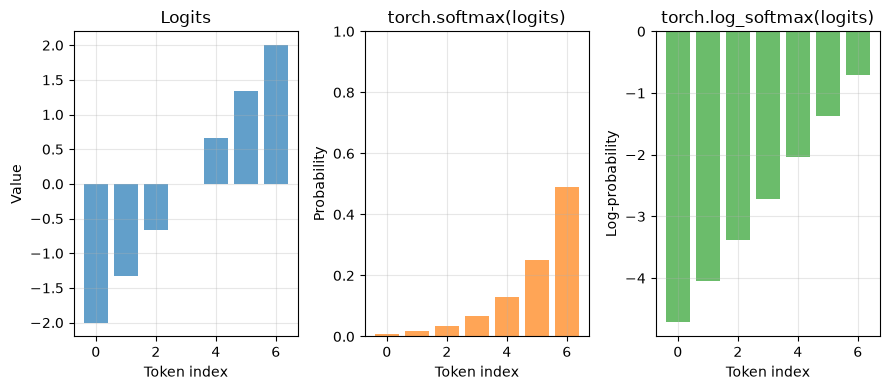

In [14]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 4))

plt.subplot(1, 3, 1)
plt.bar(range(len(logits)), logits, color="C0", alpha=0.7)
plt.title("Logits")
plt.xlabel("Token index")
plt.ylabel("Value")
plt.grid(alpha=0.3)

plt.subplot(1, 3, 2)
plt.bar(range(len(probas)), probas, color="C1", alpha=0.7)
plt.title("torch.softmax(logits)")
plt.xlabel("Token index")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.grid(alpha=0.3)

plt.subplot(1, 3, 3)
plt.bar(range(len(log_probas)), log_probas, color="C2", alpha=0.7)
plt.title("torch.log_softmax(logits)")
plt.xlabel("Token index")
plt.ylabel("Log-probability")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("logits_softmax_log_softmax.pdf")
plt.show()

In [15]:
@torch.inference_mode()
def calc_next_token_logprobas(model, tokenizer, prompt, device, show=True):

    token_ids = torch.tensor(tokenizer.encode(prompt), device=device)

    logits = model(token_ids.unsqueeze(0)).squeeze(0)
    all_logprobas = torch.log_softmax(logits, dim=-1)

    t_idx = torch.arange(0, token_ids.shape[0] - 1, device=device)
    next_ids = token_ids[1:]
    next_token_logprobas = all_logprobas[t_idx, next_ids]

    sum_next_token_logprobas = torch.sum(next_token_logprobas)

    if show:
        print("Next-token log-probabilities:", next_token_logprobas)
        print("Joint log-probability:", sum_next_token_logprobas)
    else:
        return next_token_logprobas, sum_next_token_logprobas

In [ ]:
calc_next_token_logprobas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Berlin"
    )

Next-token log-probabilities: tensor([-9.7500, -0.8164, -4.1250, -0.3008, -1.8594], dtype=torch.bfloat16)
Joint log-probability: tensor(-16.8750, dtype=torch.bfloat16)


In [ ]:
###### na podstawie moznenia probs
#  Next-token probabilities: tensor([5.7936e-05, 4.4141e-01, 1.6113e-02, 7.3828e-01, 1.5625e-01],
#        dtype=torch.bfloat16)
# Joint probability: tensor(4.7730e-08, dtype=torch.bfloat16)

##### "odzyskane" z logprop 
# Next-token log-probabilities: tensor([-9.7500e+00, -8.1641e-01, -4.1250e+00, -3.0078e-01, -1.8594e+00],
#        dtype=torch.bfloat16)
# Joint log-probability: tensor(-1.6875e+01, dtype=torch.bfloat16)
# Next-token exp(log-probabilities): tensor([5.8413e-05, 4.4141e-01, 1.6113e-02, 7.4219e-01, 1.5625e-01],
#        dtype=torch.bfloat16)
# Joint exp(log-probability): tensor(4.6799e-08, dtype=torch.bfloat16)
torch.set_printoptions(precision=4, sci_mode=True)
next_token_logprobas, sum_next_token_logprobas = calc_next_token_logprobas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Berlin",
        show=False,
    )
print("Next-token log-probabilities:", next_token_logprobas)
print("Joint log-probability:", sum_next_token_logprobas)
print("Next-token exp(log-probabilities):", torch.exp(next_token_logprobas))
print("Joint exp(log-probability):", torch.exp(sum_next_token_logprobas))

Next-token log-probabilities: tensor([-9.7500e+00, -8.1641e-01, -4.1250e+00, -3.0078e-01, -1.8594e+00],
       dtype=torch.bfloat16)
Joint log-probability: tensor(-1.6875e+01, dtype=torch.bfloat16)
Next-token exp(log-probabilities): tensor([5.8413e-05, 4.4141e-01, 1.6113e-02, 7.4219e-01, 1.5625e-01],
       dtype=torch.bfloat16)
Joint exp(log-probability): tensor(4.6799e-08, dtype=torch.bfloat16)


In [17]:
calc_next_token_logprobas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Bridge"
    )

Next-token log-probabilities: tensor([ -9.7500,  -0.8164,  -4.1250,  -0.3008, -15.0000],
       dtype=torch.bfloat16)
Joint log-probability: tensor(-30., dtype=torch.bfloat16)
